In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer         

In [20]:
data = load_breast_cancer()

X = pd.DataFrame(data.data,columns=data.feature_names)
Y = pd.Series((data.target == 0).astype(int))

print(X.shape)
print(Y.shape)

print(Y.value_counts())
print("class names: ",data.target_names)


(569, 30)
(569,)
0    357
1    212
Name: count, dtype: int64
class names:  ['malignant' 'benign']


In [6]:
class_counts = Y.value_counts().sort_index()
class_distribution = pd.DataFrame({
    'class':data.target_names,
    'counts': class_counts.values,
    'probability': class_counts.values/len(Y)
})

print(class_distribution)

       class  counts  probability
0  malignant     357     0.627417
1     benign     212     0.372583


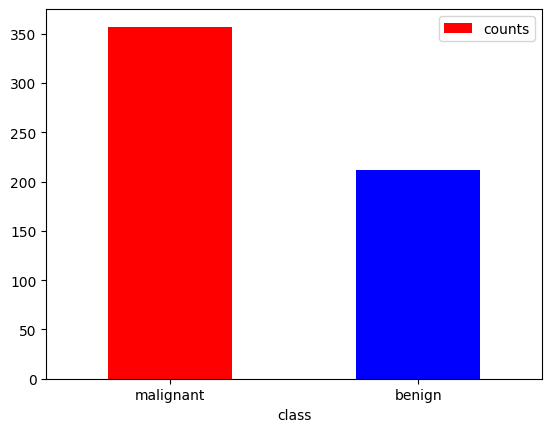

In [10]:
import matplotlib.pyplot as plt

class_distribution.plot(
    x = 'class',
    y = 'counts',
    kind = 'bar',
    color = ["red", 'blue']
)
plt.xticks(rotation = 0)
plt.show()


Train Test split

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
xtrain,xtest,ytrain,ytest = train_test_split(X,Y,test_size=0.2,random_state=42,stratify=Y)

print(xtrain.shape)
print(xtest.shape)
print(ytrain.shape)
print(ytest.shape)

(455, 30)
(114, 30)
(455,)
(114,)


In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(xtrain,ytrain)

,steps,"[('standardscaler', ...), ('logisticregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [14]:
probabilities = model.predict_proba(xtest)
print(probabilities[:5])

[[9.99635432e-01 3.64568116e-04]
 [1.07465986e-08 9.99999989e-01]
 [9.57432053e-01 4.25679471e-02]
 [4.23812678e-01 5.76187322e-01]
 [4.90844511e-01 5.09155489e-01]]


In [ ]:
results = pd.DataFrame({
    "classses": ytest.values,
    "P_malignant":probabilities[:,0],
    "P_benign": probabilities[:,1]
})

results.head()

,classses,P_malignant,P_benign
0,0,9.996354e-01,0.000365
1,1,1.074660e-08,1.000000
2,0,9.574321e-01,0.042568
3,1,4.238127e-01,0.576187
4,0,4.908445e-01,0.509155


In [21]:
threshold = 0.5 

results["Predicted_malignant"] = (
    results["P_malignant"]>= threshold
).astype(int)
results["Predicted_label"] = (
    results["Predicted_malignant"].map({
        0:"malignant",
        1:"benign"
    })
)

print(
    results[["classses","P_malignant","Predicted_label"]].head(10)
)

   classses   P_malignant Predicted_label
0         0  9.996354e-01          benign
1         1  1.074660e-08       malignant
2         0  9.574321e-01          benign
3         1  4.238127e-01       malignant
4         0  4.908445e-01       malignant
5         0  9.993840e-01          benign
6         1  2.384659e-01       malignant
7         0  9.989878e-01          benign
8         0  9.994313e-01          benign
9         0  9.892324e-01          benign


Problem: A hospital records 500 patients. Of these, 150 have a fever, 120 have a cough, and 80 have both a fever and a cough.

Write a Python program to calculate:
1. The probability of having a cough given fever.
2. The probability of fever given cough.
3. The probability of having either fever or cough.
4. Whether fever and cough are independent events.
Your task: Use the given counts, calculate the probabilities, and print meaningful output.

In [ ]:
total = 500
fever = 150
cough = 120
f_and_c = 80

p_f = fever/total
p_c = cough/total

p_c_g_f =  f_and_c/fever

print("Answer 1: ",p_c_g_f)

Answer 1:  0.5333333333333333


In [24]:
p_f_g_c = f_and_c/cough
print("ANswer 2: ",p_f_g_c)

ANswer 2:  0.6666666666666666


In [26]:
either  = fever + cough - f_and_c
p_either = either/total

print("Answer 3: ",p_either)

Answer 3:  0.38


In [27]:
#check Independence P(a int b) = p(a) . p(b)

p_f_and_c = f_and_c/total

if p_f_and_c == (p_f * p_c):
    print("both are independent events")
else:
    print("Both are not independent events")

Both are not independent events


Problem: A factory produces electronic components, and each component has a 5% probability of being defective. Assume each component is independent.

Write code to calculate:
1. The probability that exactly 3 out of 20 components are defective.
2. The probability that at most 2 are defective.
3. The probability that at least 1 is defective.
4. The expected number of defective components.
5. How the results change when the defect probability increases from 5% to 10%.

In [55]:
p = 0.05
sample_size=20

samples = np.random.binomial(n=5,p=p, size=sample_size)
print(samples)

[0 0 0 0 1 0 1 0 1 0 0 1 0 1 2 0 0 0 0 0]
